In [1]:
%pylab inline
import gc
import os
import smatch
import numpy as np

import pandas as pd
import matplotlib
import astropy.io.fits as pyfits
import matplotlib.pyplot as plt
from astropy.table import Table,join,vstack
import matplotlib.ticker as mtick
from matplotlib.colors import LogNorm


import sim_analysis_utilities as utilities

allFname='./wrkDir/database/smallcat-wl-s19-2.fits'

def makePlot(data,ax,scale='linear'):
    weight_data =   np.ones(len(data))

    counts1= np.histogram2d(data['snr'], data['res'], 32, weights=weight_data, range=[[10,80],[0.3,1]], normed=True)[0]
    ax.contour(counts1.T,extent=[10,80,0.3,1],cmap='viridis', levels=[0.01, 0.025, 0.05, 0.075])
    if scale == 'linear':
        im=ax.hist2d(data['snr'], data['res'], 128, weights=weight_data, range=[[10,80],[0.3,1]], cmap='gray_r',normed=True,vmax=0.08,alpha=0.8);
    elif scale=='log':
        im=ax.hist2d(data['snr'], data['res'], 128, weights=weight_data, range=[[10,80],[0.3,1]], cmap='gray_r',normed=True,vmax=0.08,alpha=0.8,norm=LogNorm());
    ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%d'))
    ax.set_xlabel('CModel SNR')
    ax.set_ylabel('reGaus resolution')
    plt.colorbar(im[3])
    return ax

Populating the interactive namespace from numpy and matplotlib


In [2]:
data =   pyfits.getdata(allFname)

In [3]:
"""
# Basic Mask
"""
mask    =   np.ones(len(data),dtype=bool)
mask    &=  (data['npass']>=2)     # npass
mask    &=  (data['logb']<=-0.375) # log(blendedness_abs)
mask    &=  (data['res']>0.3)  # CModel Resolution
mask    &=  (data['snr']>10.)  # CModel SNR
mask    &=  (data['absE']<2.)  # |e| of reGaus ellipticities
mask    &=  (data['mag']<24.5) # Cmodel Magnitude
mask    &=  (data['magA10']<25.5) # 

In [4]:
data1   =   data[mask]

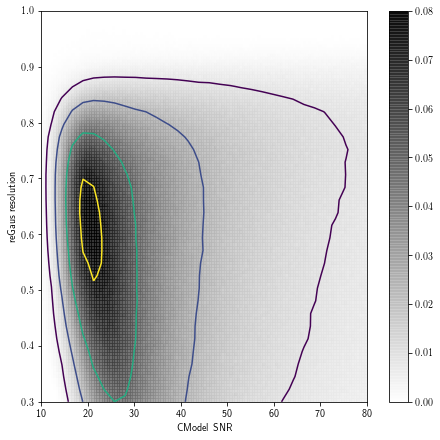

In [39]:
fig1,ax1 = plt.subplots(1,1,figsize=(6, 6),constrained_layout=True)
makePlot(data1,ax1)

In [17]:
mask2=mask& (data['tract']==9813)
data2=data[mask2]

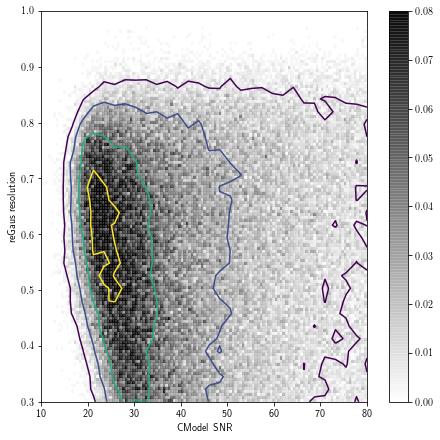

In [40]:
fig2,ax2 = plt.subplots(1,1,figsize=(6, 6),constrained_layout=True)
makePlot(data2,ax2)

In [53]:
pwd

'/work/xiangchong.li/superonionGW/code/G3sim-s18a/notebook/calibration'

In [2]:
testFname='./wrkDir/database/s19-test/tracts/9813.fits'

In [4]:
data2=utilities.make_smallcat_obs(testFname,'nan')

/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1335: RuntimeWarning: invalid value encountered in power
  size = (gal_mxx * gal_myy - gal_mxy**2)**(0.25)
/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:942: UserWarning: cannot find column for s19A Mask I
  warnings.warn('cannot find column for s19A Mask I')
/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:954: UserWarning: cannot find column for s19A Mask II
  warnings.warn('cannot find column for s19A Mask II')
/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1038: RuntimeWarning: invalid value encountered in true_divide
  snrloc    =   catalog['i_localbackground_flux']/catalog['i_localbackground_fluxerr']
/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1195: RuntimeWarning: invalid value encountered in greater_equ

In [5]:
fdfc=utilities.get_FDFC_flag(data2,version='s19')

NSIDE = 1024
ORDERING = RING in fits file
INDXSCHM = IMPLICIT
Ordering converted to NEST


In [9]:
mask2    =   np.ones(len(data2),dtype=bool)
mask2    &=  (data2['npass']>=2)     # npass
mask2    &=  (data2['logb']<=-0.375) # log(blendedness_abs)
mask2    &=  (data2['res']>0.3)  # CModel Resolution
mask2    &=  (data2['snr']>10.)  # CModel SNR
mask2    &=  (data2['absE']<2.)  # |e| of reGaus ellipticities
mask2    &=  (data2['mag']<24.5) # Cmodel Magnitude
mask2    &=  (data2['magA10']<25.5) # 
mask2    &=  fdfc

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/astropy/table/column.py:991: RuntimeWarning: invalid value encountered in less_equal
  result = getattr(super(), op)(other)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/astropy/table/column.py:991: RuntimeWarning: invalid value encountered in greater
  result = getattr(super(), op)(other)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/astropy/table/column.py:991: RuntimeWarning: invalid value encountered in less
  result = getattr(super(), op)(other)


In [10]:
np.sum(mask2)

0

In [15]:
data2['magA10']

nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
